# Filbin 2018 — 04 · EMT-TF expression

The expression step is **unconditional** — the final notebook regardless of gate outcomes (here
numbered 04: Gate 1 GO / Gate 2 GO non-branching / Gate 3 NA -> four notebooks). From a panel
spanning Snail/Zeb/Twist **and** the FOXC/PRRX mesenchymal families (VIM is a marker, not a TF, and
is excluded), we keep factors with detectable expression on this dataset and read the earliest and
latest along pseudotime, shown as thresholded expressers over the grey manifold (categorical overlay,
consistent orientation).

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read the processed manifold; use signatures.h5ad for the house linear layout + pseudotime
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # consistent orientation across all panels
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 2259 | pseudotime 0.0 -> 9.62


### Detection-gated EMT-TF panel; derive the early/late pair
Score each candidate by expressed fraction and its early/late means along pseudotime; keep detectable
factors (frac > 0.03) and take the earliest and latest by Spearman ρ vs pseudotime.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, _ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable TFs (frac>0.03): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC2      0.004       0.028      0.004    -0.040    EARLY(root)
 FOXC1      0.003       0.011      0.001    -0.019    EARLY(root)
TWIST2      0.001       0.002      0.000    -0.012    EARLY(root)
TWIST1      0.002       0.002      0.008     0.023 LATE(terminus)
 PRRX2      0.012       0.018      0.039     0.031 LATE(terminus)
 SNAI2      0.032       0.113      0.165     0.033 LATE(terminus)
 SNAI1      0.081       0.307      0.347     0.052 LATE(terminus)
 PRRX1      0.565       1.829      2.218     0.098 LATE(terminus)
  ZEB1      0.785       2.954      3.907     0.130 LATE(terminus)
  ZEB2      0.772       2.388      3.310     0.160 LATE(terminus)

detectable TFs (frac>0.03): ['SNAI2', 'SNAI1', 'PRRX1', 'ZEB1', 'ZEB2']
derived pair: SNAI2 (early/root) <-> ZEB2 (late/terminus)


### Deliverable — `expression.pdf` (thresholded expressers on grey manifold)
Categorical overlay: cells above the upper-quartile-among-expressers threshold for each of the two
derived TFs are coloured over the grey manifold; display cutoffs prevent an outlier-washed scale.

overlay thresholds (upper quartile among expressers): {'SNAI2': 5.4, 'ZEB2': 4.75} | cells shown: {'SNAI2': 18, 'ZEB2': 436}
SNAI2: 3.2% expressing; 18 shown, mean pseudotime of shown = 0.41 (all = 0.46)
ZEB2: 77.2% expressing; 436 shown, mean pseudotime of shown = 0.44 (all = 0.46)
saved expression.pdf


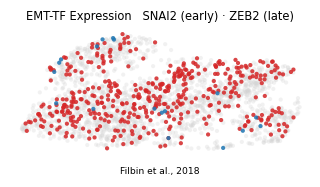

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],2) for g in [early_tf,late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5, -.14, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')